# JS09 - Lab Assignment 2: Nearest-Track Search on Micro Spotify

In [1]:
!pip install annoy faiss-cpu hnswlib kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 7.6 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 21.9 MB/s  0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520034 sha256=17b9fa95a05c09f9c50e2d9379bfe63be8eb246b96db1ddf3545f0552e7d3abd
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679797 sha256=ecfedac1c1d660f73fdc1d6f4e1ddeeee6c3649d1744cfd80c7c7a14ca069052
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50

In [2]:
import glob
import pandas as pd
import numpy as np
import time
import faiss
import hnswlib
import kagglehub
from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

In [3]:
kagglehub.login()
path = kagglehub.dataset_download('bwandowando/spotify-songs-with-attributes-and-lyrics')
print('Downloaded to:', path)

csvs = glob.glob(path + '/**/*.csv', recursive=True)
print('CSV files:', csvs)

audio_csv = next((f for f in csvs if 'danceability' in pd.read_csv(f, nrows=0).columns), None)
if audio_csv is None:
    raise FileNotFoundError('No CSV with a danceability column found')
print('Using:', audio_csv)

100%|██████████| 894M/894M [00:10<00:00, 93.4MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20
CSV files: ['/root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_lyrics_and_timestamps.csv', '/root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_attributes_and_lyrics.csv']
Using: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_attributes_and_lyrics.csv
Kaggle credentials set.
Kaggle credentials successfully validated.


In [4]:
wanted = ['name', 'track_name', 'song_name', 'title', 'artists', 'artist', 'artist_name',
          'danceability', 'energy', 'loudness', 'speechiness',
          'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

df = pd.read_csv(audio_csv, usecols=lambda c: c in wanted)

SAMPLE_N = 300_000
if SAMPLE_N and len(df) > SAMPLE_N:
    df = df.sample(SAMPLE_N, random_state=42).reset_index(drop=True)

print(df.shape)
df.head()

(300000, 11)


,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,Dans La Nuit,Sarah Brightman,0.325,0.291,-11.897,0.0349,0.968000,0.10900,0.1080,0.140,86.843
1,"Herbei, o ihr Gläubigen",Traditional;Friedrich Oberschelp;Christfried B...,0.325,0.107,-17.440,0.0389,0.983000,0.00000,0.1000,0.346,109.271
2,Who Am I?,Bazzi,0.592,0.514,-6.353,0.0329,0.517000,0.00000,0.1770,0.222,87.997
3,Stabwound Intercourse,Gorgasm,0.242,0.978,-7.627,0.1030,0.000022,0.86100,0.0941,0.193,105.342
4,Un Baile A Beneficio,Osvaldo Pugliese,0.709,0.403,-9.114,0.0678,0.966000,0.00009,0.0949,0.881,109.604


In [5]:
candidates = ['danceability', 'energy', 'loudness', 'speechiness',
              'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
features = [f for f in candidates if f in df.columns]
print('Features used:', features)

df = df.dropna(subset=features).reset_index(drop=True)

X = df[features].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype('float32')

k = 10
n, dim = X_scaled.shape
print(n, dim)

Features used: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
300000 9


In [6]:
results = {}

start = time.time()
exact = NearestNeighbors(n_neighbors=k + 1, algorithm='brute', metric='euclidean').fit(X_scaled)
results['Exact NN'] = {'build': time.time() - start}

start = time.time()
annoy_index = AnnoyIndex(dim, 'euclidean')
for i, v in enumerate(X_scaled):
    annoy_index.add_item(i, v)
annoy_index.build(10)
results['ANNOY'] = {'build': time.time() - start}

start = time.time()
nlist = int(min(1000, max(16, 4 * np.sqrt(n))))
quantizer = faiss.IndexFlatL2(dim)
faiss_index = faiss.IndexIVFFlat(quantizer, dim, nlist, faiss.METRIC_L2)
train = X_scaled if n <= 200_000 else X_scaled[np.random.choice(n, 200_000, replace=False)]
faiss_index.train(train)
faiss_index.add(X_scaled)
faiss_index.nprobe = 10
results['FAISS'] = {'build': time.time() - start}

start = time.time()
hnsw_index = hnswlib.Index(space='l2', dim=dim)
hnsw_index.init_index(max_elements=n, ef_construction=200, M=16)
hnsw_index.add_items(X_scaled)
hnsw_index.set_ef(100)
results['HNSW'] = {'build': time.time() - start}

pd.DataFrame(results).T

,build
Exact NN,0.009757
ANNOY,4.417703
FAISS,1.317567
HNSW,54.749338


In [7]:
def search_exact(q):
    return exact.kneighbors(q.reshape(1, -1), n_neighbors=k + 1)[1][0][1:]

def search_annoy(q):
    return annoy_index.get_nns_by_vector(q, k + 1, search_k=1000)[1:]

def search_faiss(q):
    return faiss_index.search(q.reshape(1, -1), k + 1)[1][0][1:]

def search_hnsw(q):
    return hnsw_index.knn_query(q.reshape(1, -1), k=k + 1)[0][0][1:]

SEARCHERS = {'Exact NN': search_exact, 'ANNOY': search_annoy, 'FAISS': search_faiss, 'HNSW': search_hnsw}

In [8]:
name_col = next((c for c in ['name', 'track_name', 'song_name', 'title'] if c in df.columns), None)
artist_col = next((c for c in ['artists', 'artist', 'artist_name'] if c in df.columns), None)
show_cols = [c for c in (name_col, artist_col) if c]

query_id = 0
print('Query track:')
display(df.loc[[query_id], show_cols] if show_cols else df.loc[[query_id], features])

for algo, fn in SEARCHERS.items():
    ids = list(fn(X_scaled[query_id]))
    print(f'\n{algo}')
    display(df.loc[ids, show_cols] if show_cols else df.loc[ids, features])

Query track:


,name,artists
0,Dans La Nuit,Sarah Brightman



Exact NN


,name,artists
39320,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
87041,Revolutions,Nobuo Uematsu
184188,We Have All The Time In The World,Alfie Boe
184252,Kahit Konting Pagtingin,Sharon Cuneta
6847,This One's From The Heart,"Tom Waits, Crystal Gayle"
86813,MORNING PRAYER,Minako Yoshida
31093,Waiting,Alice Boman
70836,Nella Fantasia,Jackie Evancho
263767,Monsoon,Hippo Campus
179145,Temptation - Remastered - 1992,Perry Como



ANNOY


,name,artists
39320,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
87041,Revolutions,Nobuo Uematsu
184188,We Have All The Time In The World,Alfie Boe
184252,Kahit Konting Pagtingin,Sharon Cuneta
6847,This One's From The Heart,"Tom Waits, Crystal Gayle"
86813,MORNING PRAYER,Minako Yoshida
31093,Waiting,Alice Boman
70836,Nella Fantasia,Jackie Evancho
263767,Monsoon,Hippo Campus
179145,Temptation - Remastered - 1992,Perry Como



FAISS


,name,artists
39320,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
87041,Revolutions,Nobuo Uematsu
184188,We Have All The Time In The World,Alfie Boe
184252,Kahit Konting Pagtingin,Sharon Cuneta
6847,This One's From The Heart,"Tom Waits, Crystal Gayle"
86813,MORNING PRAYER,Minako Yoshida
31093,Waiting,Alice Boman
70836,Nella Fantasia,Jackie Evancho
263767,Monsoon,Hippo Campus
179145,Temptation - Remastered - 1992,Perry Como



HNSW


,name,artists
39320,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
87041,Revolutions,Nobuo Uematsu
184188,We Have All The Time In The World,Alfie Boe
184252,Kahit Konting Pagtingin,Sharon Cuneta
6847,This One's From The Heart,"Tom Waits, Crystal Gayle"
86813,MORNING PRAYER,Minako Yoshida
31093,Waiting,Alice Boman
70836,Nella Fantasia,Jackie Evancho
263767,Monsoon,Hippo Campus
179145,Temptation - Remastered - 1992,Perry Como


In [9]:
n_queries = 200
rng = np.random.default_rng(42)
query_ids = rng.choice(n, n_queries, replace=False)

truth = [set(search_exact(X_scaled[i])) for i in query_ids]

rows = []
for algo, fn in SEARCHERS.items():
    start = time.time()
    preds = [set(fn(X_scaled[i])) for i in query_ids]
    qtime = (time.time() - start) * 1000 / n_queries
    rec = np.mean([len(p & t) / k for p, t in zip(preds, truth)])
    rows.append({'Algorithm': algo,
                 'Build (s)': results[algo]['build'],
                 'Query (ms/query)': qtime,
                 'Recall@10': rec})

comparison = pd.DataFrame(rows).set_index('Algorithm').round(4)
comparison

,Build (s),Query (ms/query),Recall@10
Algorithm,,,
Exact NN,0.0098,12.4013,1.000
ANNOY,4.4177,0.2300,0.996
FAISS,1.3176,0.0721,0.988
HNSW,54.7493,0.1073,0.998


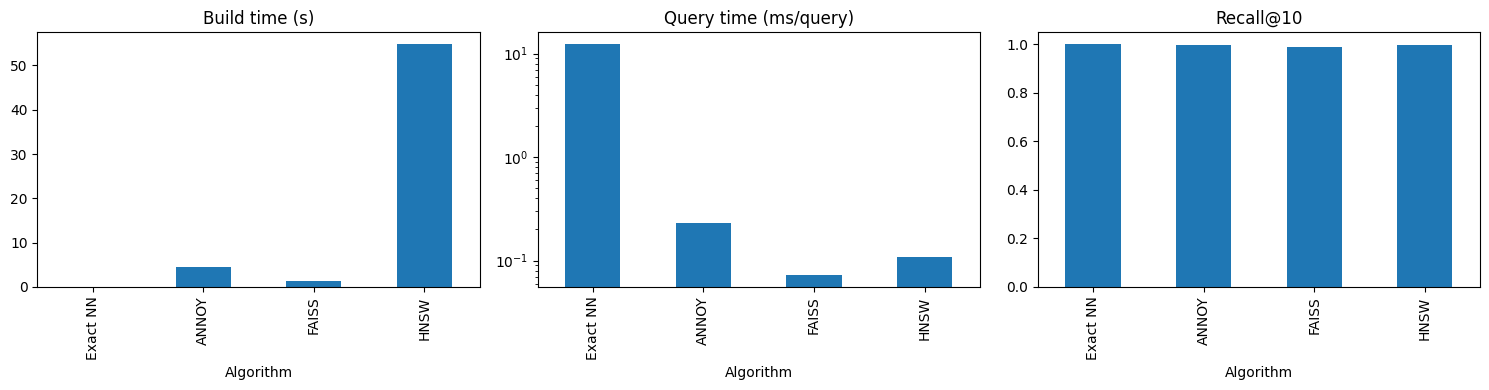

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
comparison['Build (s)'].plot(kind='bar', ax=axes[0], title='Build time (s)')
comparison['Query (ms/query)'].plot(kind='bar', ax=axes[1], title='Query time (ms/query)', logy=True)
comparison['Recall@10'].plot(kind='bar', ax=axes[2], title='Recall@10', ylim=(0, 1.05))
plt.tight_layout()
plt.show()

## Analysis

- **Exact NN** is the reference: recall is 1 by definition, but each query scans every track.
- **ANNOY, FAISS (IVF) and HNSW** answer each query much faster and return mostly the same tracks; their recall is the price paid for speed.
- **HNSW** typically gives the highest recall at a given speed but has the longest build time and memory use. **ANNOY** builds fast and is simple. **FAISS IVF** depends on `nprobe`: raising it improves recall and slows queries.
- Check the table above for the exact numbers on this dataset.